In [2]:
try:
    from google.colab import output
    print('Running on CoLab')
    #%pip install roboticstoolbox-python>=1.0.2
    %pip install git+https://github.com/petercorke/robotics-toolbox-python@future
    %pip install spatialmath-python>=1.1.5
    %pip install --no-deps rvc3python
    %pip install bdsim
    COLAB = True
except ModuleNotFoundError:
    COLAB = False

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

%matplotlib widget

In [3]:
from IPython.display import HTML

import matplotlib.pyplot as plt

# add RTB examples folder to the path
import sys, os.path
import RVC3 as rvc
models_dir = os.path.join(rvc.__path__[0], 'models')
sys.path.append(models_dir)

# ------ standard imports ------ #
import numpy as np
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *
from roboticstoolbox import *

### Car-Like Vehicle

┌────────────┬────┬────┬───────────┬────────┬──────────┬─────────────────────┐
│   block    │ nc │ nd │   type    │ inport │  source  │     source type     │
├────────────┼────┼────┼───────────┼────────┼──────────┼─────────────────────┤
│ scopexy1.0 │ 0  │ 0  │ scopexy1  │ 0      │ vehicle  │ ndarray(3,).float64 │
├────────────┼────┼────┼───────────┼────────┼──────────┼─────────────────────┤
│ speed      │ 0  │ 0  │ constant  │        │          │                     │
├────────────┼────┼────┼───────────┼────────┼──────────┼─────────────────────┤
│ steering@  │ 0  │ 0  │ piecewise │        │          │                     │
├────────────┼────┼────┼───────────┼────────┼──────────┼─────────────────────┤
│ vehicle    │ 3  │ 0  │ bicycle   │ 0      │ speed    │ int                 │
│            │    │    │           │ 1      │ steering │ int                 │
└────────────┴────┴────┴───────────┴────────┴──────────┴─────────────────────┘

Note: @ = event source


>>> Start simulation: T = 

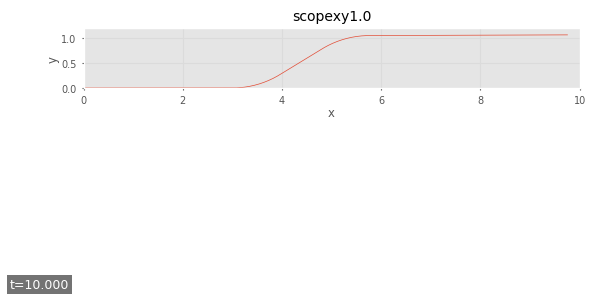


<<< Simulation complete
  block diagram evaluations: 1877
    of which ydot calls:     1666  (remaining are post-integration replay + sink passes)
  bd.evaluate() mean time:   138.5 us/call  (total 260.1 ms)
  clocktime speedup:         1.26x  (simulated 10s in 7933.4 ms)
  integration time points:   211
  scheduled event intervals: 200  (each bounded by a clock tick, scheduled event, or terminal marker)
  integrator wall time:       0.372 s  (solve_ivp only; excludes post-integration replay)
  zero-crossing events:      0



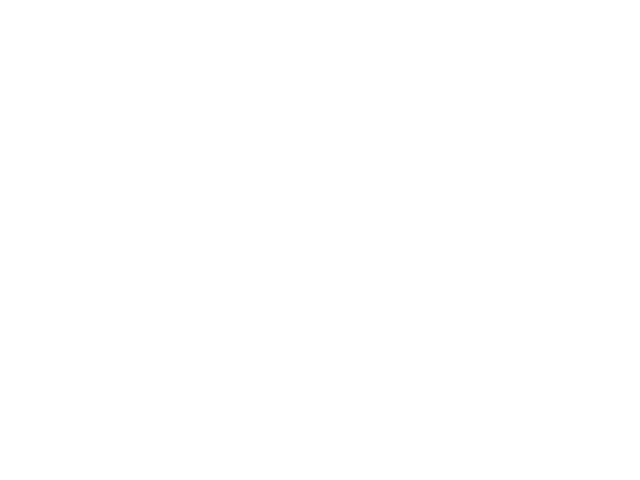

In [3]:
%run -i "models_dir\lanechange.py"

In [4]:
out

t      = ndarray:float64 (211,)
x      = ndarray:float64 (211, 3)
xnames = ['x', 'y', '$\\theta$'] (list)

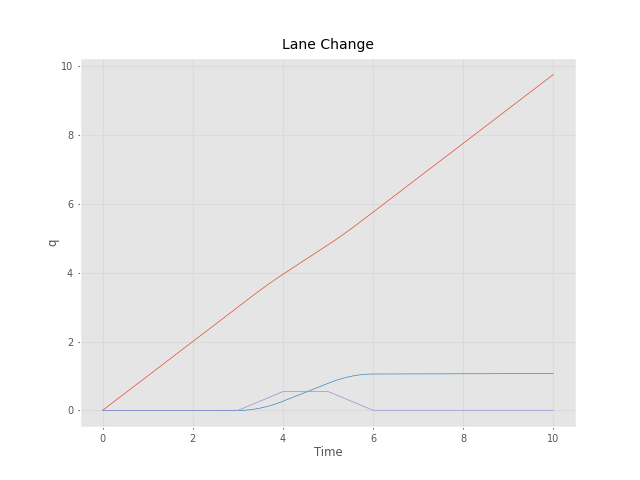

In [5]:
plt.plot(out.t, out.x)  # q vs time
plt.xlabel('Time')
plt.ylabel('q')
plt.title('Lane Change')
plt.show()

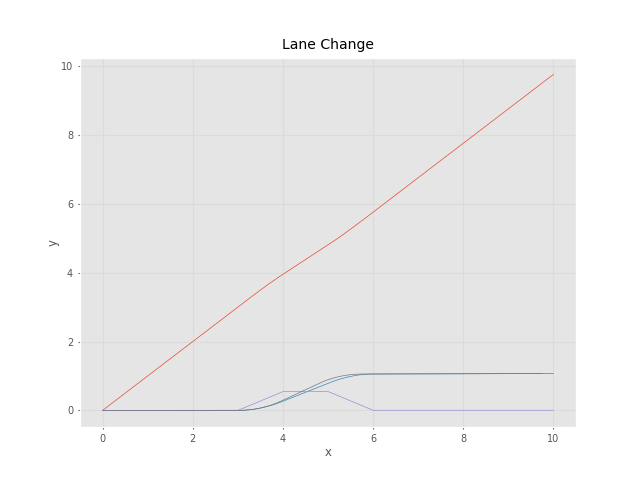

In [6]:
plt.plot(out.x[:,0], out.x[:,1])# x vs y
plt.xlabel('x')
plt.ylabel('y')
plt.title('Lane Change')
plt.show()

#### Driving to a Point

In [7]:
pgoal = (5, 5)

(5, 5)

In [8]:
qs = (8, 5, pi/2)

(8, 5, 1.5707963267948966)

┌───────────────┬────┬────┬─────────────┬────────┬────────────┬─────────────────────┐
│     block     │ nc │ nd │    type     │ inport │   source   │     source type     │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ function.0    │ 0  │ 0  │ function    │ 0      │ sum.0      │ ndarray(2,).float64 │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ function.1    │ 0  │ 0  │ function    │ 0      │ sum.0      │ ndarray(2,).float64 │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ gain.0        │ 0  │ 0  │ gain        │ 0      │ function.0 │ float               │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ gain.1        │ 0  │ 0  │ gain        │ 0      │ sum.1      │ float               │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ goal          │ 0  │ 0  │ constant    │        │    

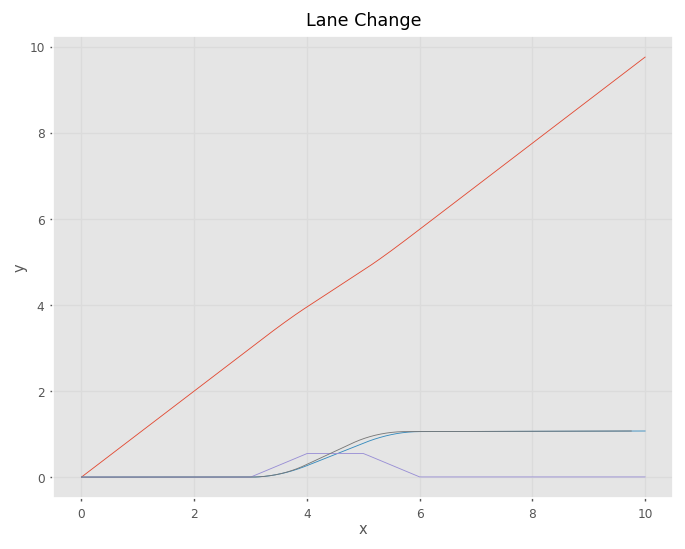

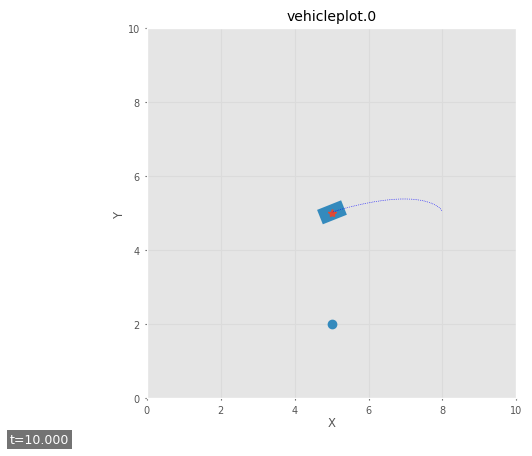

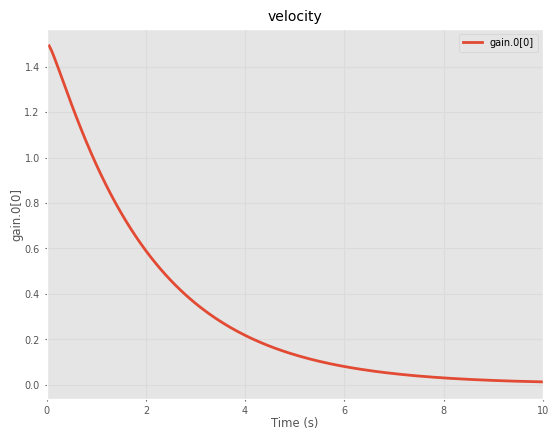

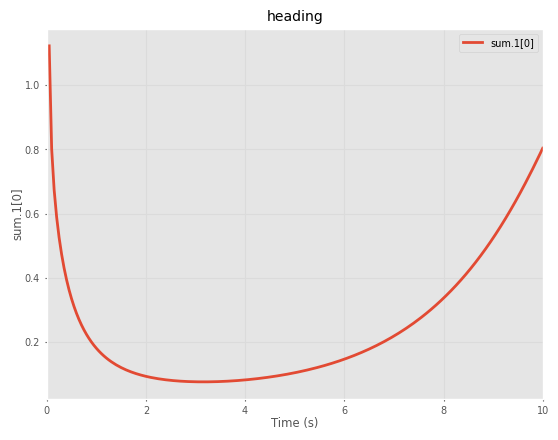


<<< Simulation complete
  block diagram evaluations: 1800
    of which ydot calls:     1600  (remaining are post-integration replay + sink passes)
  bd.evaluate() mean time:   352.6 us/call  (total 634.6 ms)
  clocktime speedup:         0.21x  (simulated 10s in 47747.2 ms)
  integration time points:   200
  scheduled event intervals: 200  (each bounded by a clock tick, scheduled event, or terminal marker)
  integrator wall time:       0.651 s  (solve_ivp only; excludes post-integration replay)
  zero-crossing events:      0



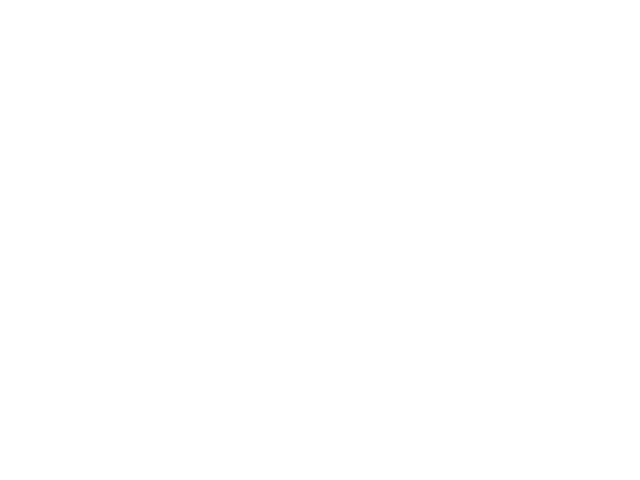

In [9]:
%run -i "models_dir/drivepoint.py"

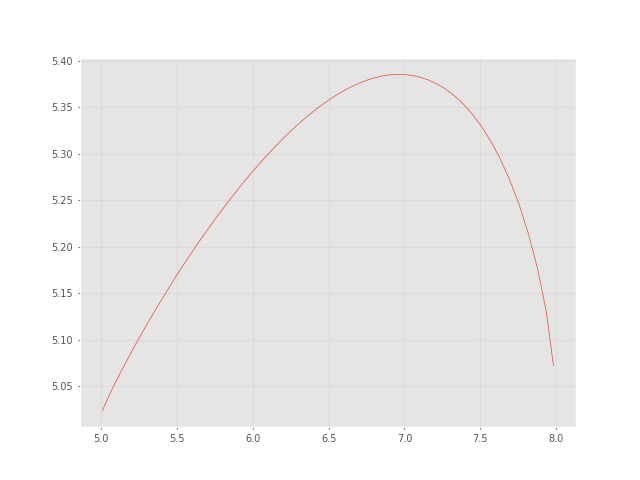

In [10]:
q = out.x
plt.plot(q[:,0], q[:, 1])
plt.show()

#### Driving Along a Line

In [11]:
L = (1, -2, 4)

(1, -2, 4)

In [12]:
qs = (8, 5, pi/2)

(8, 5, 1.5707963267948966)

┌───────────────┬────┬────┬─────────────┬────────┬────────────┬─────────────────────┐
│     block     │ nc │ nd │    type     │ inport │   source   │     source type     │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ Kd            │ 0  │ 0  │ gain        │ 0      │ function.0 │ float64             │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ Kh            │ 0  │ 0  │ gain        │ 0      │ sum.0      │ float               │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ constant.0    │ 0  │ 0  │ constant    │        │            │                     │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ constant.1    │ 0  │ 0  │ constant    │        │            │                     │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ function.0    │ 0  │ 0  │ function    │ 0      │ xy 

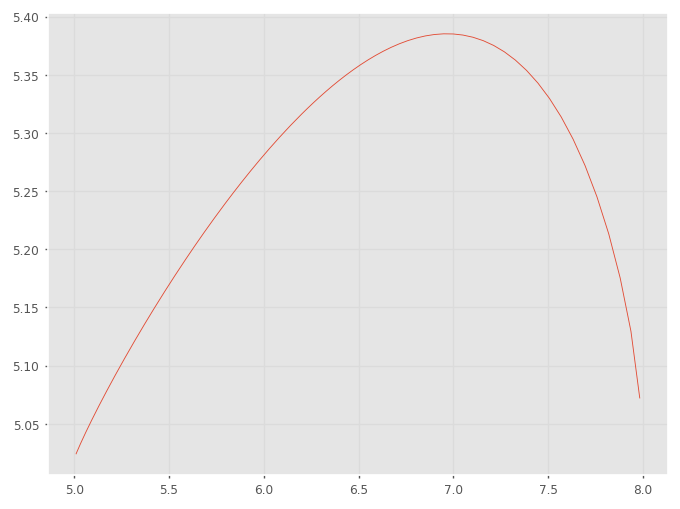

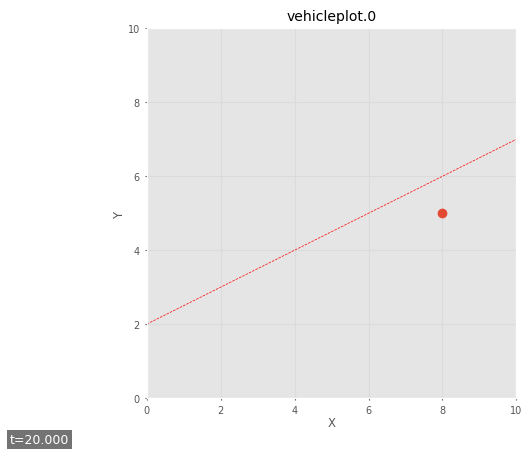

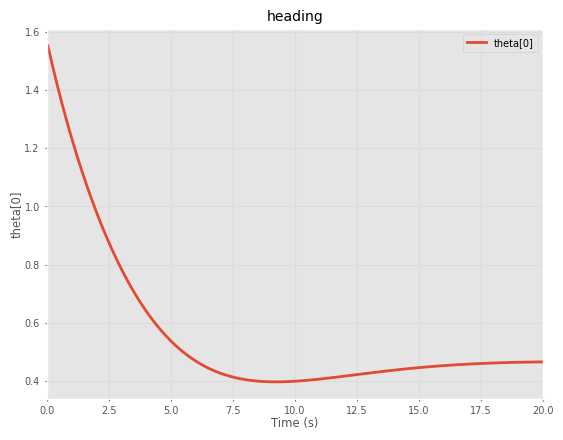


<<< Simulation complete
  block diagram evaluations: 3600
    of which ydot calls:     3200  (remaining are post-integration replay + sink passes)
  bd.evaluate() mean time:   346.9 us/call  (total 1248.8 ms)
  clocktime speedup:         0.26x  (simulated 20s in 75720.4 ms)
  integration time points:   400
  scheduled event intervals: 400  (each bounded by a clock tick, scheduled event, or terminal marker)
  integrator wall time:       1.374 s  (solve_ivp only; excludes post-integration replay)
  zero-crossing events:      0



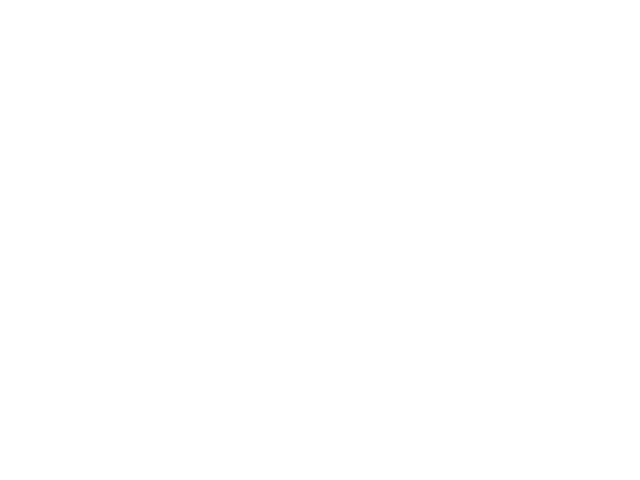

In [13]:
%run -i "models_dir/driveline.py"

In [ ]:
%matplotlib widget

q = out.x
plt.plot(q[:,0], q[:, 1])
plt.show()


#### Driving Along a Path

(405, 2)
┌───────────────┬────┬────┬─────────────┬────────┬──────────────┬─────────────────────┐
│     block     │ nc │ nd │    type     │ inport │    source    │     source type     │
├───────────────┼────┼────┼─────────────┼────────┼──────────────┼─────────────────────┤
│ Kh            │ 0  │ 0  │ gain        │ 0      │ herr         │ float               │
├───────────────┼────┼────┼─────────────┼────────┼──────────────┼─────────────────────┤
│ bicycle.0     │ 3  │ 0  │ bicycle     │ 0      │ speed        │ int                 │
│               │    │    │             │ 1      │ Kh           │ float               │
├───────────────┼────┼────┼─────────────┼────────┼──────────────┼─────────────────────┤
│ close_enough  │ 0  │ 0  │ stop        │ 0      │ xy           │ ndarray(2,).int64   │
├───────────────┼────┼────┼─────────────┼────────┼──────────────┼─────────────────────┤
│ err           │ 0  │ 0  │ sum         │ 0      │ pure_pursuit │ ndarray(2,).float64 │
│               │    │ 

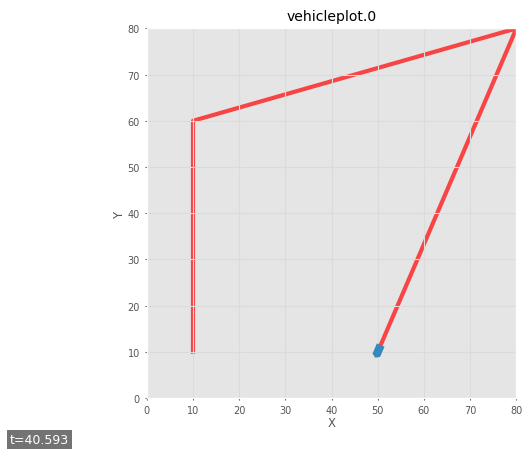

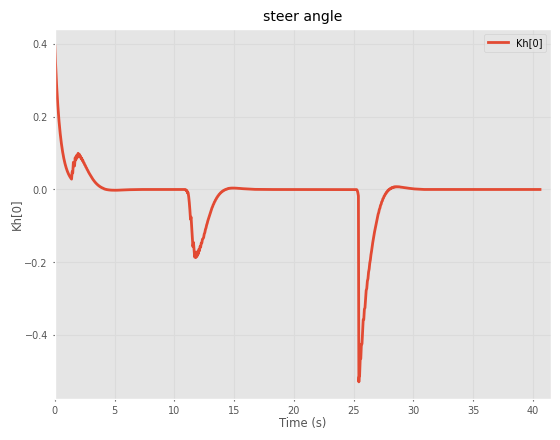

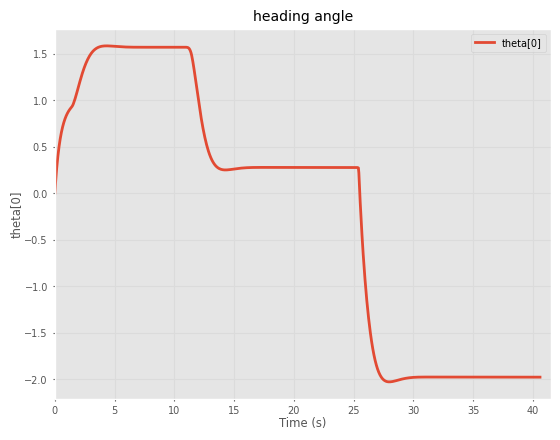


--- stop requested at t=40.5932 by Block.sink('close_enough', type=stop, nin=1)

<<< Simulation complete
  block diagram evaluations: 9007
    of which ydot calls:     6520  (remaining are post-integration replay + sink passes)
  bd.evaluate() mean time:   345.3 us/call  (total 3109.8 ms)
  clocktime speedup:         0.23x  (simulated 41.5s in 182425.3 ms)
  integration time points:   816
  scheduled event intervals: 812  (each bounded by a clock tick, scheduled event, or terminal marker)
  integrator wall time:       4.010 s  (solve_ivp only; excludes post-integration replay)
  zero-crossing events:      1
    close_enough: 1



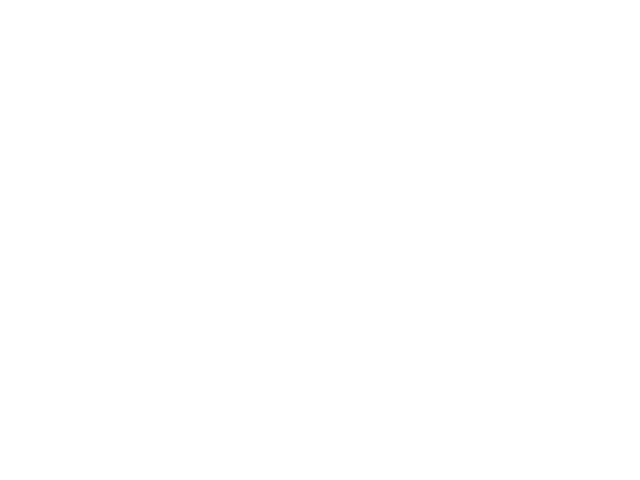

In [3]:
%run -i "models_dir/drivepursuit.py"

#### Driving to a Configuration

In [4]:
qg = (5, 5, pi / 2)

(5, 5, 1.5707963267948966)

In [5]:
qs = (9, 5, 0)

(9, 5, 0)

alpha -1.5707963267948966
set direction to  1
┌───────────────┬────┬────┬─────────────┬────────┬──────────────┬───────────────────┐
│     block     │ nc │ nd │    type     │ inport │    source    │    source type    │
├───────────────┼────┼────┼─────────────┼────────┼──────────────┼───────────────────┤
│ Kalpha        │ 0  │ 0  │ gain        │ 0      │ polar[2]     │ float64           │
├───────────────┼────┼────┼─────────────┼────────┼──────────────┼───────────────────┤
│ Kbeta         │ 0  │ 0  │ gain        │ 0      │ sum.1        │ float             │
├───────────────┼────┼────┼─────────────┼────────┼──────────────┼───────────────────┤
│ Krho          │ 0  │ 0  │ gain        │ 0      │ polar[1]     │ float             │
├───────────────┼────┼────┼─────────────┼────────┼──────────────┼───────────────────┤
│ abs           │ 0  │ 0  │ function    │ 0      │ vprod        │ float             │
├───────────────┼────┼────┼─────────────┼────────┼──────────────┼───────────────────┤
│ alpha 

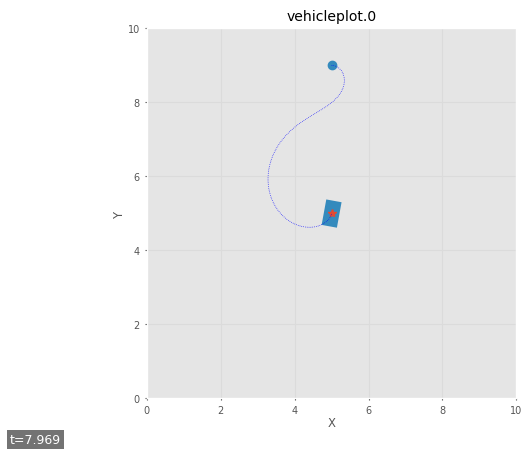

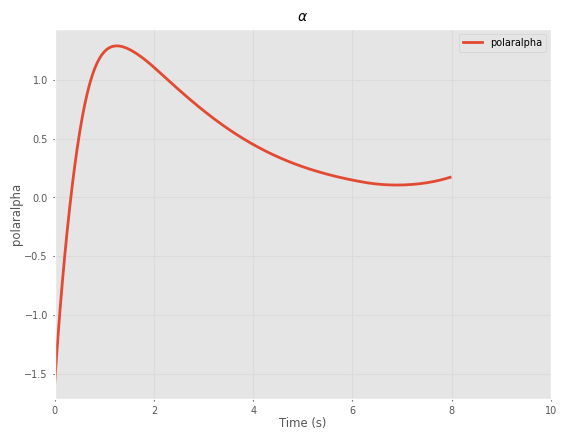

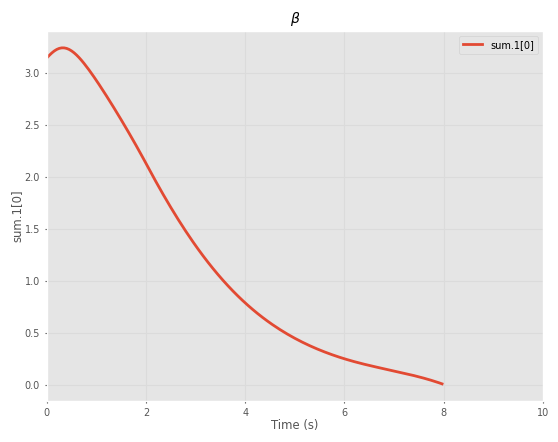

alpha -1.5707963267948966
set direction to  1

<<< Simulation complete
  block diagram evaluations: 1837
    of which ydot calls:     1304  (remaining are post-integration replay + sink passes)
  bd.evaluate() mean time:   315.0 us/call  (total 578.6 ms)
  clocktime speedup:         0.32x  (simulated 10s in 31267.2 ms)
  integration time points:   164
  scheduled event intervals: 160  (each bounded by a clock tick, scheduled event, or terminal marker)
  integrator wall time:       0.736 s  (solve_ivp only; excludes post-integration replay)
  zero-crossing events:      1
    close enough: 1



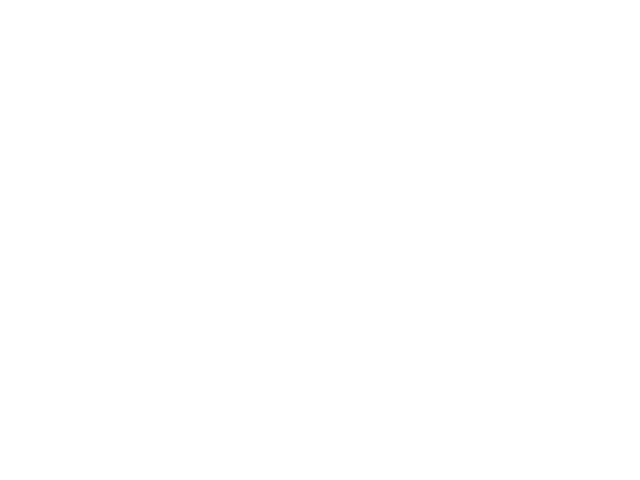

In [6]:
%run -i "models_dir/driveconfig.py"

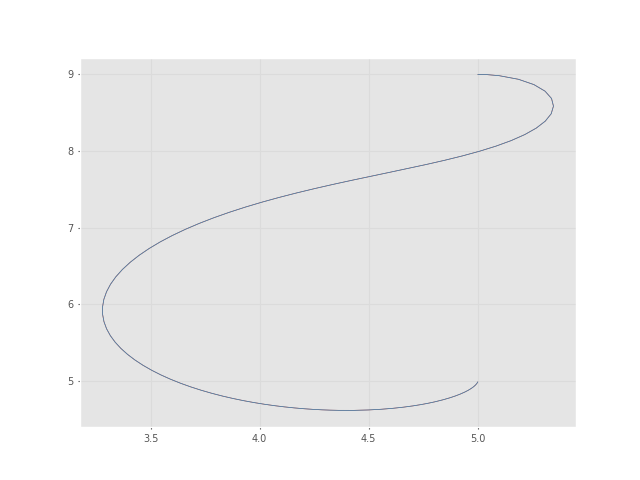

In [8]:
q = out.x  # configuration vs time
plt.plot(q[:, 0], q[:, 1])
plt.show()